
# Similar Animals, Different Pixels
### A Gaussian Naive Bayes Experiment on CIFAR-10

**Berkay Aydin**  
CS 436 - Introduction to Machine Learning  
Assignment 4

## Introduction

For this assignment, I used three classes from the CIFAR-10 dataset: horse, deer, and dog. I chose these animals because they have some similar visual features, especially in their colors and backgrounds. I wanted to see how well Gaussian Naive Bayes could separate them using only pixel values.

I used 5,000 training images and 100 test images from each class. I calculated the mean, variance, and prior probability for each class without using a built-in classifier. After testing the model, I compared the predictions with the actual labels and calculated the accuracy and model size.


## 1. Loading the CIFAR-10 Dataset

I will start by loading the CIFAR-10 dataset and checking the dimensions of the training and test sets. Each image contains 32 × 32 pixels with three color channels (RGB).


In [11]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10

# Load the original training and test sets
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)


Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)



## 2. Selecting the Three Classes

I selected horse (7), deer (4), and dog (5) from the CIFAR-10 dataset. I will use 5,000 training images and 100 test images from each class.

The original training and test sets will remain separate so that the model is evaluated on images that were not used during training.


In [12]:

# Select horse, deer, and dog images
selected_classes = [7, 4, 5]

y_train = y_train.flatten()
y_test = y_test.flatten()

train_images = []
train_labels = []
test_images = []
test_labels = []

for label in selected_classes:
    train_idx = np.where(y_train == label)[0][:5000]
    test_idx = np.where(y_test == label)[0][:100]

    train_images.append(x_train[train_idx])
    train_labels.append(y_train[train_idx])

    test_images.append(x_test[test_idx])
    test_labels.append(y_test[test_idx])

train_images = np.concatenate(train_images)
train_labels = np.concatenate(train_labels)

test_images = np.concatenate(test_images)
test_labels = np.concatenate(test_labels)

print("Training images:", train_images.shape)
print("Test images:", test_images.shape)

for label, name in zip(selected_classes, ["Horse", "Deer", "Dog"]):
    print(name, ":", np.sum(train_labels == label), "training,",
          np.sum(test_labels == label), "testing")


Training images: (15000, 32, 32, 3)
Test images: (300, 32, 32, 3)
Horse : 5000 training, 100 testing
Deer : 5000 training, 100 testing
Dog : 5000 training, 100 testing



## 3. Visualizing the Selected Images

Before preparing the images for the model, I want to look at a few examples from each class. This will help me understand the visual similarities and differences between horses, deer, and dogs in the dataset.


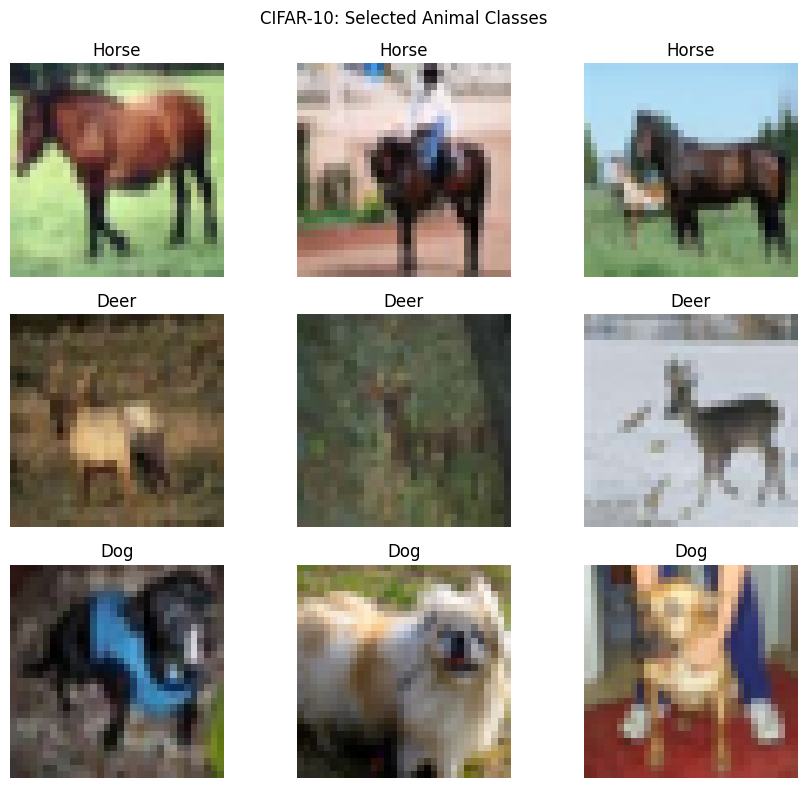

In [13]:

# Display three images from each class
animal_names = ["Horse", "Deer", "Dog"]

plt.figure(figsize=(9, 8))

for i, label in enumerate(selected_classes):
    indices = np.where(train_labels == label)[0]

    for j in range(3):
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(train_images[indices[j]])
        plt.title(animal_names[i])
        plt.axis("off")

plt.suptitle("CIFAR-10: Selected Animal Classes")
plt.tight_layout()
plt.show()



## 4. Preparing the Images for Gaussian Naive Bayes

The images are currently stored as 32 × 32 RGB arrays. Since Gaussian Naive Bayes works with numerical features, I will flatten each image into a vector of 3,072 pixel values.

I will also scale the pixel values from 0–255 to 0–1. I will apply the same preprocessing to both the training and test images.


In [14]:

# Convert each RGB image into 3072 features
X_train = train_images.reshape(15000, 3072)
X_test = test_images.reshape(300, 3072)

# Scale pixel values between 0 and 1
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Training data: (15000, 3072)
Test data: (300, 3072)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 5. Calculating Class Statistics

For each class, I calculated the mean and variance of all 3,072 pixel features using the training images. These values describe how the pixel values are distributed within each class.

I also calculated the class priors. Since I used 5,000 training images for each animal, all three classes have the same prior probability of approximately 0.3333.

I added a small value (1e-6) to the variances to prevent division by zero when calculating the Gaussian likelihoods.

In [15]:

# Calculate mean, variance, and prior for each animal
class_means = []
class_variances = []
class_priors = []

for label in selected_classes:
    animal_images = X_train[train_labels == label]

    mean = np.mean(animal_images, axis=0)
    variance = np.var(animal_images, axis=0) + 1e-6
    prior = len(animal_images) / len(X_train)

    class_means.append(mean)
    class_variances.append(variance)
    class_priors.append(prior)

class_means = np.array(class_means)
class_variances = np.array(class_variances)
class_priors = np.array(class_priors)

print("Means shape:", class_means.shape)
print("Variances shape:", class_variances.shape)

for i, name in enumerate(animal_names):
    print(name, "prior:", round(class_priors[i], 4))


Means shape: (3, 3072)
Variances shape: (3, 3072)
Horse prior: 0.3333
Deer prior: 0.3333
Dog prior: 0.3333


## 6. Implementing Gaussian Naive Bayes Prediction

After calculating the class statistics, I used them to predict the labels of the test images. For each image, I calculated a Gaussian log-likelihood score for horse, deer, and dog using the mean and variance values of each class.

Instead of multiplying the individual likelihoods, I used logarithms to avoid numerical underflow. I also included the class prior in each score. The class with the highest final score was selected as the prediction.

In [16]:

# Predict the class of each test image using Gaussian Naive Bayes
predictions = []

for image in X_test:
    scores = []

    for i in range(len(selected_classes)):
        mean = class_means[i]
        variance = class_variances[i]

        log_likelihood = -0.5 * np.sum(
            np.log(2 * np.pi * variance) +
            ((image - mean) ** 2) / variance
        )

        score = np.log(class_priors[i]) + log_likelihood
        scores.append(score)

    predicted_class = selected_classes[np.argmax(scores)]
    predictions.append(predicted_class)

predictions = np.array(predictions)

print("Number of predictions:", len(predictions))
print("First 10 predictions:", predictions[:10])
print("First 10 actual labels:", test_labels[:10])


Number of predictions: 300
First 10 predictions: [5 4 7 4 5 5 4 7 7 7]
First 10 actual labels: [7 7 7 7 7 7 7 7 7 7]


## 7. Evaluating the Model Accuracy

I compared the predicted labels with the actual test labels to measure the accuracy of the model. Out of 300 test images, 146 were classified correctly, resulting in an overall accuracy of 48.67%.

I also calculated the accuracy for each class separately to see how the model performed on horses, deer, and dogs.

In [17]:

# Calculate the overall accuracy
correct_predictions = np.sum(predictions == test_labels)
accuracy = correct_predictions / len(test_labels) * 100

print("Correct predictions:", correct_predictions, "out of", len(test_labels))
print("Overall accuracy:", round(accuracy, 2), "%")

print("\nAccuracy for each animal:")

for i, label in enumerate(selected_classes):
    animal_test = test_labels == label

    correct = np.sum(predictions[animal_test] == test_labels[animal_test])
    total = np.sum(animal_test)
    animal_accuracy = correct / total * 100

    print(animal_names[i], ":", correct, "/", total,
          "correct -", round(animal_accuracy, 2), "%")


Correct predictions: 146 out of 300
Overall accuracy: 48.67 %

Accuracy for each animal:
Horse : 50 / 100 correct - 50.0 %
Deer : 56 / 100 correct - 56.0 %
Dog : 40 / 100 correct - 40.0 %


## 8. Analyzing Classification Errors

To examine the incorrect predictions, I created a confusion matrix for the three classes. The rows represent the actual labels, while the columns represent the predicted labels.

This allowed me to see which animals were confused with each other and how often the model made these mistakes. The diagonal values show the correct predictions for each class.

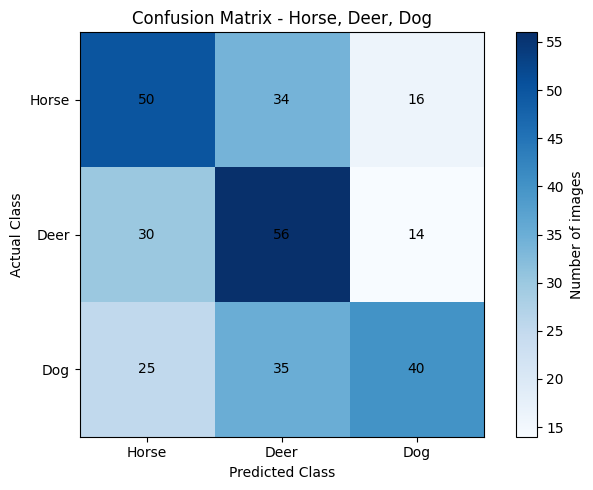

In [18]:

# Build a confusion matrix for the three animal classes
confusion = np.zeros((3, 3), dtype=int)

for actual, predicted in zip(test_labels, predictions):
    row = selected_classes.index(actual)
    col = selected_classes.index(predicted)
    confusion[row, col] += 1

plt.figure(figsize=(7, 5))
plt.imshow(confusion, cmap="Blues")
plt.colorbar(label="Number of images")

plt.xticks(range(3), animal_names)
plt.yticks(range(3), animal_names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Horse, Deer, Dog")

for i in range(3):
    for j in range(3):
        plt.text(j, i, confusion[i, j],
                 ha="center", va="center", color="black")

plt.tight_layout()
plt.show()


## 9. Model Size and Probability Calculations

After testing the model, I calculated the number of values needed to store its parameters. Each class has 3,072 pixel features, and the model stores a mean and a variance for every feature, along with one class prior.

This gives a total of 18,435 stored values: 9,216 means, 9,216 variances, and 3 priors.

For each test image, the model evaluates 9,216 Gaussian feature likelihoods across the three classes. Since the test set contains 300 images, the total number of likelihood evaluations is 2,764,800.

In [19]:

# Count the values stored in the model
num_means = class_means.size
num_variances = class_variances.size
num_priors = class_priors.size

total_values = num_means + num_variances + num_priors

# Count Gaussian likelihood calculations during testing
features_per_image = X_test.shape[1]
number_of_classes = len(selected_classes)

calculations_per_image = features_per_image * number_of_classes
total_calculations = calculations_per_image * len(X_test)

print("Stored mean values:", num_means)
print("Stored variance values:", num_variances)
print("Stored prior values:", num_priors)
print("Total stored values:", total_values)

print("\nGaussian likelihood calculations:")
print("For one test image:", calculations_per_image)
print("For all test images:", total_calculations)


Stored mean values: 9216
Stored variance values: 9216
Stored prior values: 3
Total stored values: 18435

Gaussian likelihood calculations:
For one test image: 9216
For all test images: 2764800



## 10. Results and Discussion

### Classification Results

The Gaussian Naive Bayes model correctly classified 146 out of 300 test images, giving an overall accuracy of 48.67%.

The accuracy for each class was:

| Class | Correct Predictions | Accuracy |
|---|---|---|
| Horse | 50 / 100 | 50% |
| Deer | 56 / 100 | 56% |
| Dog | 40 / 100 | 40% |

Deer had the highest accuracy, while dog had the lowest.

### Classification Errors

I originally expected horse and deer to be difficult to distinguish because of their similar colors and natural backgrounds.

The confusion matrix shows that 34 horse images were classified as deer, and 30 deer images were classified as horse. However, the model also classified 35 dog images as deer.

This suggests that the model has difficulty separating all three classes, rather than only confusing horses and deer.

One possible reason is that Gaussian Naive Bayes treats pixel features as conditionally independent. This assumption does not capture the relationships between neighboring pixels that help describe the shape of an animal.

### Model Size

Each image contains 3,072 pixel features. For each of the three classes, the model stores a mean and a variance for every feature, along with one class prior.

- Mean values: 3 × 3,072 = 9,216
- Variance values: 3 × 3,072 = 9,216
- Class prior values: 3
- Total stored values: 18,435

For one test image, the model evaluates 3 × 3,072 = 9,216 Gaussian feature likelihoods.

For all 300 test images, the total is:

300 × 9,216 = 2,764,800 Gaussian likelihood evaluations.

These counts represent the model parameters and Gaussian likelihood evaluations, rather than 18,435 stored probability values.

### Conclusion

In this assignment, I implemented Gaussian Naive Bayes using the mean, variance, and prior probability of each selected class without using a built-in classifier.

The model achieved 48.67% accuracy on the selected CIFAR-10 test images. Although it performed better than the 33.33% accuracy of always predicting one class in this balanced test set, it still made mistakes on more than half of the images.

The results show that Gaussian Naive Bayes can use pixel distributions to distinguish the classes to some extent, but its independence assumption limits how well it can represent visual patterns in images.
